# VQE：寻找更低的能量

VQE 调整量子电路的角度，让指定哈密顿量的期望值尽可能小。本例只有一个角度，可以直接观察能量下降。这里没有训练数据，因此只需要外层的优化循环。

In [1]:
from qutai import Tensor, nn, quantum, visualization

device = "apple"

## 1. 定义能量与电路

哈密顿量是 `−X₀X₁ − 0.5Z₀ − 0.5Z₁`，理论最低能量为 `−√2 ≈ −1.4142`。RY 改变角度，CNOT 把两个比特连接起来。

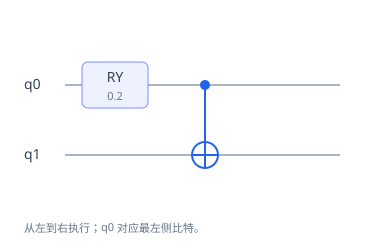

In [2]:
hamiltonian = -(quantum.X(0) @ quantum.X(1)) - 0.5 * quantum.Z(0) - 0.5 * quantum.Z(1)
angle = Tensor(0.2, device=device, requires_grad=True)
model = quantum.Circuit(2, [quantum.RY(0, angle), quantum.CNOT(0, 1)])
optimizer = nn.SGD(model, learning_rate=0.1)
visualization.Circuit(model)

## 2. 降低能量

`expectation()` 返回可求导的能量。优化器仍然只做清梯度、反向、更新这几件事。

当前能量： -1.4136284589767456


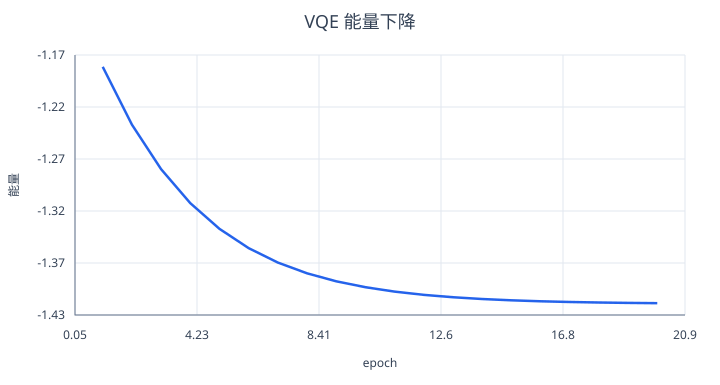

In [3]:
epochs = 20
energies = []
# 没有数据集：每轮直接优化一次当前电路的目标值。
for epoch in range(epochs):
    optimizer.zero_grad()
    loss = model.expectation(hamiltonian)
    loss.backward()
    optimizer.step()
    energies.append(loss.item())
print("当前能量：", model.expectation(hamiltonian).item())
visualization.Plot(title="VQE 能量下降", xlabel="epoch", ylabel="能量").line(range(1, epochs + 1), energies)

## 3. 看优化后的量子态

能量是训练目标，测量概率展示的是最终状态在各个计算基上的分布。它们是两种不同的读出。

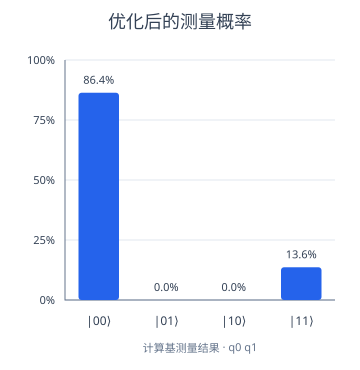

In [4]:
visualization.Probabilities(model.run(), title="优化后的测量概率")